In [62]:
import pandas as pd 
import wandb
import json


In [63]:
import importlib
import src.wandb_analysis

# Now reload the module
importlib.reload(src.wandb_analysis)

# Re-import the functions
from src.wandb_analysis import (get_best_worst_all,
                                get_array_metric, get_metric,
                                plot_run,get_hp_vals, plot_run)

In [64]:
import numpy as np

In [65]:
api = wandb.Api()

In [73]:
n_c = [12,16][::-1]

distr = ["imb_0.99","imb_5.0","iid"]
dt_name = ["adult_TargEncoded"]#["diamond_1_hot"]#"diamond_1_hot","dry_bean","adult_TargEncoded"
#dt_name = ["diamond_1_hot",
dt_name = ["dry_bean"]

In [74]:

#distr = distr[:2]
dt_name=dt_name[:1]

HPSearchs = []
sweep_names = []
prefix = "Sweep"#"Sweep","FdSwp"
prefix_sweeep = "best_federated"
# ask user if it wants to fill the # of clients
z_fill = input("Do you want to fill the number of clients? (y/n) adult has to").lower()
z_fill = True
print(z_fill)
for d in distr:
    for dt in dt_name:
        for num_c in n_c:
            n_c_str = str(num_c).zfill(2) if z_fill else str(num_c)
            HPSearchs.append("_".join([prefix,dt,n_c_str,d]))
            sweep_names.append("_".join([prefix_sweeep,dt,n_c_str]))
            
for e in zip(HPSearchs,sweep_names):
    print(e)

True
('Sweep_dry_bean_16_imb_0.99', 'best_federated_dry_bean_16')
('Sweep_dry_bean_12_imb_0.99', 'best_federated_dry_bean_12')
('Sweep_dry_bean_16_imb_5.0', 'best_federated_dry_bean_16')
('Sweep_dry_bean_12_imb_5.0', 'best_federated_dry_bean_12')
('Sweep_dry_bean_16_iid', 'best_federated_dry_bean_16')
('Sweep_dry_bean_12_iid', 'best_federated_dry_bean_12')


In [75]:
hyperparameters = [
    # Model architecture parameters
    "hidden_units", 
    "layers", 
    "dropout",
    
    # Training parameters
    "batch_size", 
    "learning_rate", 
    "momentum", 
    "class_weight",

    # Federated parameters
    "local_epochs",
    "num_rounds",
    
    # Performance metrics
    "global/val_f1_macro",
    "global/train_f1_macro",
    "test_f1_macro"
]

In [76]:
# get the projects
projects = api.projects()
# sort the projects by name
HPSearchs = []
for p in projects:
    if dt_name[0] in p.name:
        print(p.name)
        HPSearchs.append(p.name)
        # check if there are sweeps
        sweeps = p.sweeps()
        print(len(sweeps),sweeps[0].name)
        

Sweep_dry_bean_04_imb_100000
1 best_federated_dry_bean_4
Sweep_dry_bean_08_imb_100000
1 best_federated_dry_bean_8
Sweep_dry_bean_12_imb_100000
2 best_federated_dry_bean_12
Sweep_dry_bean_16_imb_100000
1 best_federated_dry_bean_16
Sweep_dry_bean_04_imb_0.99
1 best_federated_dry_bean_4
Sweep_dry_bean_08_imb_0.99
1 best_federated_dry_bean_8
Sweep_dry_bean_12_imb_0.99
2 best_federated_dry_bean_12
Sweep_dry_bean_16_imb_0.99
1 best_federated_dry_bean_16
Sweep_dry_bean_04_imb_5
1 best_federated_dry_bean_4
Sweep_dry_bean_08_imb_5
1 best_federated_dry_bean_8
Sweep_dry_bean_12_imb_5
1 best_federated_dry_bean_12
Sweep_dry_bean_16_imb_5
1 best_federated_dry_bean_16
Sweep_dry_bean_16_imb_10000
1 best_federated_dry_bean_16
Sweep_dry_bean_08_imb_10000
1 best_federated_dry_bean_8
FdSwp_dry_bean_4_iid
2 best_federated_dry_bean_4
FdSwp_dry_bean_8_iid
1 best_federated_dry_bean_8
FdSwp_dry_bean_16_iid
1 best_federated_dry_bean_16
FdSwp_dry_bean_4_imb_0.99
2 best_federated_dry_bean_4
FdSwp_dry_bean_8_imb_0

In [77]:
print(sorted(HPSearchs))

['FdSwp_dry_bean_16_iid', 'FdSwp_dry_bean_16_imb_0.50', 'FdSwp_dry_bean_16_imb_0.99', 'FdSwp_dry_bean_4_iid', 'FdSwp_dry_bean_4_imb_0.50', 'FdSwp_dry_bean_4_imb_0.99', 'FdSwp_dry_bean_8_iid', 'FdSwp_dry_bean_8_imb_0.50', 'FdSwp_dry_bean_8_imb_0.99', 'Sweep_dry_bean_04_imb_0.99', 'Sweep_dry_bean_04_imb_100000', 'Sweep_dry_bean_04_imb_5', 'Sweep_dry_bean_08_imb_0.99', 'Sweep_dry_bean_08_imb_10000', 'Sweep_dry_bean_08_imb_100000', 'Sweep_dry_bean_08_imb_5', 'Sweep_dry_bean_12_imb_0.99', 'Sweep_dry_bean_12_imb_100000', 'Sweep_dry_bean_12_imb_5', 'Sweep_dry_bean_16_imb_0.99', 'Sweep_dry_bean_16_imb_10000', 'Sweep_dry_bean_16_imb_100000', 'Sweep_dry_bean_16_imb_5']


In [78]:
# get best run from a sweep
command_list, summary_list, config_list, name_list = [], [], [], []
for proj in HPSearchs:
    print(proj)
    sweeps = api.project(proj).sweeps()
    print(str(sweeps))
    # how many runs in the sweep
    print(len(sweeps[0].runs))


    
    dates = []
    for s in sweeps:
        sweep_id = s.id
        sweep_complete_name = "/".join(["vale_valerio",proj,sweep_id])
        sweep = api.sweep(sweep_complete_name)
        print(sweep.name,len(sweep.runs),"HERE"*10)
        if len(sweep.runs) == 0:
            dates.append("2000-01-01T00:00:00.000Z")
        else:   
            dates.append(sweep.runs[0].created_at)
    
    # now sort the sweeps by date
    sweep_id = [(d,x.id) for d,x in sorted(zip(dates,sweeps))]
    print("Latest run is at",sweep_id)
    sweep_id = sweep_id[-1][1]
    print("choosing:",sweep_id)
    sweep_complete_name = "/".join(["vale_valerio",proj,sweep_id])
    sweep = api.sweep(sweep_complete_name)
    print(sweep.name,len(sweep.runs),"HERE"*10)
    run = sweep.best_run()
    all_dict = {k:v for k,v in run.summary._json_dict.items() }
        #summary_list.append()


        # .config contains the hyperparameters.
        #  We remove special values that start with _.
    for k,v in run.config.items():
            if not k.startswith('_'):
                all_dict[k]= v
    config_list.append(all_dict)
        # .name is the human-readable name of the run.
    name_list.append(run.name)
    meta = run.file("wandb-metadata.json").download(replace=True)
    meta = json.load(meta)
    command = " ".join([meta["program"]] + meta["args"])
    print(proj, run.name)
    for m in ["global/val_f1_macro","global/train_f1_macro","test_f1_macro"]:
        print(m, np.round(run.summary[m]*100,2))
    print(command)
    command_list.append(command)

runs_df = pd.DataFrame({
        #"summary": summary_list,
        "proj": HPSearchs,
        "config": config_list,
        "name": name_list,
        "command": command_list
        })
    

Sweep_dry_bean_04_imb_100000
[<Sweep vale_valerio/Sweep_dry_bean_04_imb_100000/g1e79jrm (Unknown State)>]
0


wandb: Sorting runs by -summary_metrics.global/val_f1_macro


best_federated_dry_bean_4 30 HEREHEREHEREHEREHEREHEREHEREHEREHEREHERE
Latest run is at [('2024-03-29T18:33:51', 'g1e79jrm')]
choosing: g1e79jrm
best_federated_dry_bean_4 30 HEREHEREHEREHEREHEREHEREHEREHEREHEREHERE
Sweep_dry_bean_04_imb_100000 devoted-sweep-6
global/val_f1_macro 94.71
global/train_f1_macro 94.18
test_f1_macro 93.71
sim.py --dataset_name dry_bean --alpha 100000 --num_clients 4 --batch_size=128 --class_weight=False --dropout=0.19544370419492493 --hidden_units=109 --layers=1 --learning_rate=0.03930277509869821 --local_epochs=2 --momentum=0.8155816769253579 --num_rounds=30
Sweep_dry_bean_08_imb_100000
[<Sweep vale_valerio/Sweep_dry_bean_08_imb_100000/dcpubwn8 (Unknown State)>]
0


wandb: Sorting runs by -summary_metrics.global/val_f1_macro


best_federated_dry_bean_8 30 HEREHEREHEREHEREHEREHEREHEREHEREHEREHERE
Latest run is at [('2024-03-29T18:16:07', 'dcpubwn8')]
choosing: dcpubwn8
best_federated_dry_bean_8 30 HEREHEREHEREHEREHEREHEREHEREHEREHEREHERE
Sweep_dry_bean_08_imb_100000 azure-sweep-25
global/val_f1_macro 93.33
global/train_f1_macro 93.84
test_f1_macro 93.97
sim.py --dataset_name dry_bean --alpha 100000 --num_clients 8 --batch_size=4 --class_weight=False --dropout=0.006518264355805714 --hidden_units=105 --layers=1 --learning_rate=0.3678178141375753 --local_epochs=4 --momentum=0.042765620128602855 --num_rounds=10
Sweep_dry_bean_12_imb_100000
[<Sweep vale_valerio/Sweep_dry_bean_12_imb_100000/w9gevxs6 (Unknown State)>, <Sweep vale_valerio/Sweep_dry_bean_12_imb_100000/17z1ttp9 (Unknown State)>]
0
best_federated_dry_bean_12 50 HEREHEREHEREHEREHEREHEREHEREHEREHEREHERE


...

best_federated_dry_bean_4 30 HEREHEREHEREHEREHEREHEREHEREHEREHEREHERE
Latest run is at [('2023-12-05T14:53:19', '2rfvdv6h')]
choosing: 2rfvdv6h
best_federated_dry_bean_4 30 HEREHEREHEREHEREHEREHEREHEREHEREHEREHERE
FdSwp_dry_bean_4_imb_0.50 glowing-sweep-19
global/val_f1_macro 84.69
global/train_f1_macro 82.48
test_f1_macro 93.21
sim.py --dataset_name dry_bean --alpha 0.5 --num_clients 4 --batch_size=32 --class_weight=False --dropout=0.03883889180675133 --hidden_units=116 --layers=1 --learning_rate=0.1337079889339007 --local_epochs=4 --momentum=0.8453732325280416 --num_rounds=50
FdSwp_dry_bean_8_imb_0.50
[<Sweep vale_valerio/FdSwp_dry_bean_8_imb_0.50/fwjjngkb (Unknown State)>]
0


wandb: Sorting runs by -summary_metrics.global/val_f1_macro


best_federated_dry_bean_8 30 HEREHEREHEREHEREHEREHEREHEREHEREHEREHERE
Latest run is at [('2023-12-05T12:46:00', 'fwjjngkb')]
choosing: fwjjngkb
best_federated_dry_bean_8 30 HEREHEREHEREHEREHEREHEREHEREHEREHEREHERE
FdSwp_dry_bean_8_imb_0.50 bright-sweep-27
global/val_f1_macro 79.73
global/train_f1_macro 79.62
test_f1_macro 93.39
sim.py --dataset_name dry_bean --alpha 0.5 --num_clients 8 --batch_size=80 --class_weight=True --dropout=0.006138202619697286 --hidden_units=115 --layers=1 --learning_rate=0.30874225498521013 --local_epochs=4 --momentum=0.8712123754819686 --num_rounds=30
FdSwp_dry_bean_16_imb_0.50
[<Sweep vale_valerio/FdSwp_dry_bean_16_imb_0.50/j5eb4v6x (Unknown State)>]
0


wandb: Sorting runs by -summary_metrics.global/val_f1_macro


best_federated_dry_bean_16 30 HEREHEREHEREHEREHEREHEREHEREHEREHEREHERE
Latest run is at [('2023-12-05T12:26:42', 'j5eb4v6x')]
choosing: j5eb4v6x
best_federated_dry_bean_16 30 HEREHEREHEREHEREHEREHEREHEREHEREHEREHERE
FdSwp_dry_bean_16_imb_0.50 sunny-sweep-29
global/val_f1_macro 88.41
global/train_f1_macro 84.82
test_f1_macro 93.38
sim.py --dataset_name dry_bean --alpha 0.5 --num_clients 16 --batch_size=128 --class_weight=True --dropout=0.0424275607904993 --hidden_units=126 --layers=1 --learning_rate=0.0768953244468545 --local_epochs=5 --momentum=0.8902851776787954 --num_rounds=50


In [79]:
sweeps

[<Sweep vale_valerio/FdSwp_dry_bean_16_imb_0.50/j5eb4v6x (Unknown State)>]

In [80]:
runs_df.head()

,proj,config,name,command
0,Sweep_dry_bean_04_imb_100000,{'client_002/val_recall_class_06': 0.873015873...,devoted-sweep-6,sim.py --dataset_name dry_bean --alpha 100000 ...
1,Sweep_dry_bean_08_imb_100000,{'client_006/train_precision_class_00': 0.9304...,azure-sweep-25,sim.py --dataset_name dry_bean --alpha 100000 ...
2,Sweep_dry_bean_12_imb_100000,"{'client_001/val_precision_class_02': 1, 'clie...",lemon-sweep-14,sim.py --dataset_name dry_bean --alpha 100000 ...
3,Sweep_dry_bean_16_imb_100000,"{'client_008/test_loss': 1.440800666809082, 'c...",sweet-sweep-22,sim.py --dataset_name dry_bean --alpha 100000 ...
4,Sweep_dry_bean_04_imb_0.99,"{'client_001/train_loss': 12.527739761746489, ...",deft-sweep-16,sim.py --dataset_name dry_bean --alpha 0.99 --...


In [81]:
list(runs_df.values[0][1].keys())[:4]


['client_002/val_recall_class_06',
 'client_002/val_precision_class_02',
 'client_003/val_loss',
 'test_recall_class_01']

In [82]:
# now take the runs in the project FEDEXAI
# and for each configuration get the same metrics for the sweep

In [83]:
# create dictionary in order to plot the best, worst client for each alpha and for each
# number of clients. The last element is the global score
scores_dict = {}
precisions_dict = {}
recalls_dict = {}
configurations = {}
for e in runs_df.values:
    print(e[0])
    print(e[-1])
    if "test_f1_weighted" in list(e[1].keys()):
        print("test_f1_weighted" in list(e[1].keys()))
        # check the values
        print(e[1]["test_f1_weighted"])
    else:
        print("test_f1_weighted, not present\nINTERRUPTED")

        continue


    b_identifier,b_score, w_identifier, w_score, all_ = get_best_worst_all(e[1],"test_f1_macro")
    _,_,_,_,all_tr = get_best_worst_all(e[1],"train_f1_macro")
    global_score_f1 = e[1]["global/val_f1_macro"]
    test_f1_score = e[1]["test_f1_macro"]
    test_acc_score = e[1]["test_accuracy"]
    scores_dict[e[0]] = [w_identifier, w_score, # 0,1
                        b_identifier, b_score,  # 2,3
                        global_score_f1,        # 4
                        all_tr, all_,           # 5,6
                        test_f1_score]          # 7
    configurations[e[0]] = e[-1]
    
    precisions_dict[e[0]] = (get_array_metric(e[1],"train_precision"),
                             get_array_metric(e[1],"test_precision"),
                             get_metric(e[1],"precision"))
    recalls_dict[e[0]] = (get_array_metric(e[1],"train_recall"),
                             get_array_metric(e[1],"test_recall"),
                             get_metric(e[1],"recall"))

Sweep_dry_bean_04_imb_100000
sim.py --dataset_name dry_bean --alpha 100000 --num_clients 4 --batch_size=128 --class_weight=False --dropout=0.19544370419492493 --hidden_units=109 --layers=1 --learning_rate=0.03930277509869821 --local_epochs=2 --momentum=0.8155816769253579 --num_rounds=30
True
0.9253853854282912
Sweep_dry_bean_08_imb_100000
sim.py --dataset_name dry_bean --alpha 100000 --num_clients 8 --batch_size=4 --class_weight=False --dropout=0.006518264355805714 --hidden_units=105 --layers=1 --learning_rate=0.3678178141375753 --local_epochs=4 --momentum=0.042765620128602855 --num_rounds=10
True
0.9289588804392231
Sweep_dry_bean_12_imb_100000
sim.py --dataset_name dry_bean --alpha 100000 --num_clients 12 --layers 2 --num_rounds 30 --batch_size=8 --class_weight=False --dropout=0.18686979048958924 --hidden_units=28 --learning_rate=0.12443168739837268 --local_epochs=5 --momentum=0.4813496691137441
True
0.9333214320173832
Sweep_dry_bean_16_imb_100000
sim.py --dataset_name dry_bean --alph

In [84]:
configurations

{'Sweep_dry_bean_04_imb_100000': 'sim.py --dataset_name dry_bean --alpha 100000 --num_clients 4 --batch_size=128 --class_weight=False --dropout=0.19544370419492493 --hidden_units=109 --layers=1 --learning_rate=0.03930277509869821 --local_epochs=2 --momentum=0.8155816769253579 --num_rounds=30',
 'Sweep_dry_bean_08_imb_100000': 'sim.py --dataset_name dry_bean --alpha 100000 --num_clients 8 --batch_size=4 --class_weight=False --dropout=0.006518264355805714 --hidden_units=105 --layers=1 --learning_rate=0.3678178141375753 --local_epochs=4 --momentum=0.042765620128602855 --num_rounds=10',
 'Sweep_dry_bean_12_imb_100000': 'sim.py --dataset_name dry_bean --alpha 100000 --num_clients 12 --layers 2 --num_rounds 30 --batch_size=8 --class_weight=False --dropout=0.18686979048958924 --hidden_units=28 --learning_rate=0.12443168739837268 --local_epochs=5 --momentum=0.4813496691137441',
 'Sweep_dry_bean_16_imb_100000': 'sim.py --dataset_name dry_bean --alpha 100000 --num_clients 16 --batch_size=128 --c

In [45]:
#scores_dict

### The best, the worst and the global average


In [85]:
import matplotlib.pyplot as plt
import os
import seaborn as sns


In [86]:


choose_conf = "Sweep_adult_TargEncoded_12_imb_5"
print(configurations[choose_conf])
ch_conf_model = " ".join(configurations[choose_conf].split(" ")[7:])
print(ch_conf_model)
new_confs = {}
for k,v in configurations.items():
    if not ("16" in k or "12" in k) or "0.5" in k:
        continue
    head = " ".join(v.split(" ")[:7])
    
    print(k,head+""+ch_conf_model)
    new_confs[k] = head+" "+ch_conf_model

KeyError: 'Sweep_adult_TargEncoded_12_imb_5'

In [51]:
import os
# create a script in bash to lounch the command of the best run
# the script is saved in the same folder of the notebook
with open("lunch_and_save_best_run_aligned_"+dt_name+".sh",'w+') as r:
    for k,v in new_confs.items():
        # sleep 10 seconds
        r.writelines("sleep 3\n")
        r.writelines("python3 "+new_confs[k]+" --no-sweep &\nwait\n")

# change the permission of the file giving the possibility to execute it
# the mode to add execution permission is 0o755
os.chmod("lunch_and_save_best_run_aligned_"+dt_name+".sh",mode=0o755)

In [52]:
!cat lunch_and_save_best_run_aligned_adult_TargEncoded.sh

sleep 3
python3 sim.py --dataset_name adult_TargEncoded --alpha 100000 --num_clients 12 --batch_size=80 --class_weight=False --dropout=0.03887079828099323 --hidden_units=81 --layers=3 --learning_rate=0.004901989861685105 --local_epochs=2 --momentum=0.43664214891225345 --num_rounds=30 --no-sweep &
wait
sleep 3
python3 sim.py --dataset_name adult_TargEncoded --alpha 0.99 --num_clients 12 --batch_size=80 --class_weight=False --dropout=0.03887079828099323 --hidden_units=81 --layers=3 --learning_rate=0.004901989861685105 --local_epochs=2 --momentum=0.43664214891225345 --num_rounds=30 --no-sweep &
wait
sleep 3
python3 sim.py --dataset_name adult_TargEncoded --alpha 5 --num_clients 12 --batch_size=80 --class_weight=False --dropout=0.03887079828099323 --hidden_units=81 --layers=3 --learning_rate=0.004901989861685105 --local_epochs=2 --momentum=0.43664214891225345 --num_rounds=30 --no-sweep &
wait
sleep 3
python3 sim.py --dataset_name adult_TargEncoded --alpha 100000 --num_clients 16 --batch_si

In [87]:
print(dt_name)
if isinstance(dt_name,list):
    dt_name = dt_name[0]
print(dt_name)

['dry_bean']
dry_bean


In [88]:
import os
# create a script in bash to lounch the command of the best run
# the script is saved in the same folder of the notebook
with open("lunch_and_save_best_run_"+dt_name+".sh",'w+') as r:
    for k,v in scores_dict.items():
        if not (("16" in k or "12" in k) and not "0.5" in k):
            continue
        print(k)
            
        # sleep 10 seconds
        r.writelines("sleep 3\n")
        r.writelines("python3 "+configurations[k]+" --no-sweep &\nwait\n")

# change the permission of the file giving the possibility to execute it
# the mode to add execution permission is 0o755
os.chmod("lunch_and_save_best_run_"+dt_name+".sh",mode=0o755)


Sweep_dry_bean_12_imb_100000
Sweep_dry_bean_16_imb_100000
Sweep_dry_bean_12_imb_0.99
Sweep_dry_bean_16_imb_0.99
Sweep_dry_bean_12_imb_5
Sweep_dry_bean_16_imb_5
Sweep_dry_bean_16_imb_10000


In [89]:
!cat lunch_and_save_best_run_{dt_name}.sh

sleep 3
python3 sim.py --dataset_name dry_bean --alpha 100000 --num_clients 12 --layers 2 --num_rounds 30 --batch_size=8 --class_weight=False --dropout=0.18686979048958924 --hidden_units=28 --learning_rate=0.12443168739837268 --local_epochs=5 --momentum=0.4813496691137441 --no-sweep &
wait
sleep 3
python3 sim.py --dataset_name dry_bean --alpha 100000 --num_clients 16 --batch_size=128 --class_weight=False --dropout=0.03482907120606822 --hidden_units=33 --layers=2 --learning_rate=0.3384896566603923 --local_epochs=4 --momentum=0.07507789639317923 --num_rounds=30 --no-sweep &
wait
sleep 3
python3 sim.py --dataset_name dry_bean --alpha 0.99 --num_clients 12 --layers 2 --num_rounds 30 --batch_size=64 --class_weight=False --dropout=0.05966957654591041 --hidden_units=124 --learning_rate=0.08918890682655946 --local_epochs=2 --momentum=0.8211109463796185 --no-sweep &
wait
sleep 3
python3 sim.py --dataset_name dry_bean --alpha 0.99 --num_clients 16 --batch_size=80 --class_weight=True --dropout=0.

In [90]:
configurations.keys()

dict_keys(['Sweep_dry_bean_04_imb_100000', 'Sweep_dry_bean_08_imb_100000', 'Sweep_dry_bean_12_imb_100000', 'Sweep_dry_bean_16_imb_100000', 'Sweep_dry_bean_04_imb_0.99', 'Sweep_dry_bean_08_imb_0.99', 'Sweep_dry_bean_12_imb_0.99', 'Sweep_dry_bean_16_imb_0.99', 'Sweep_dry_bean_04_imb_5', 'Sweep_dry_bean_08_imb_5', 'Sweep_dry_bean_12_imb_5', 'Sweep_dry_bean_16_imb_5', 'Sweep_dry_bean_16_imb_10000', 'Sweep_dry_bean_08_imb_10000'])

In [57]:
print("filled keys:")
for s in sorted(scores_dict.keys()):
    print(s)

# now we want to reorder them s.t. we have first the iid, then the imbalanced 0.99 and then the imbalanced 0.50
# and for each of them we want to have the 4,8,16 clients
ordered_keys = []
for nc in [4, 8, 12,16]:
    for d in ["imb_100000","imb_5","imb_0.99"]:
        #for dt in dt_name:
        ordered_keys.append("_".join([prefix,dt_name,str(nc).zfill(2),d]))
#print(*ordered_keys)
#


from src.wandb_analysis import get_hp_vals, check_partitions, additional_plot, plot_table
print("missing keys:")
for k in configurations.keys():
    if k not in ordered_keys:
        print(k)
    
    configurations[ordered_keys[0]]

filled keys:
Sweep_diamond_1_hot_04_iid
Sweep_diamond_1_hot_04_imb_0.50
Sweep_diamond_1_hot_04_imb_0.99
Sweep_diamond_1_hot_04_imb_5
Sweep_diamond_1_hot_08_iid
Sweep_diamond_1_hot_08_imb_0.50
Sweep_diamond_1_hot_08_imb_0.99
Sweep_diamond_1_hot_08_imb_5
Sweep_diamond_1_hot_12_imb_0.99
Sweep_diamond_1_hot_12_imb_100000
Sweep_diamond_1_hot_12_imb_5
Sweep_diamond_1_hot_16_iid
Sweep_diamond_1_hot_16_imb_0.50
Sweep_diamond_1_hot_16_imb_0.99
Sweep_diamond_1_hot_16_imb_5
missing keys:


KeyError: 'Sweep_diamond_1_hot_04_imb_100000'

In [58]:
ordered_keys

['Sweep_diamond_1_hot_04_imb_100000',
 'Sweep_diamond_1_hot_04_imb_5',
 'Sweep_diamond_1_hot_04_imb_0.99',
 'Sweep_diamond_1_hot_08_imb_100000',
 'Sweep_diamond_1_hot_08_imb_5',
 'Sweep_diamond_1_hot_08_imb_0.99',
 'Sweep_diamond_1_hot_12_imb_100000',
 'Sweep_diamond_1_hot_12_imb_5',
 'Sweep_diamond_1_hot_12_imb_0.99',
 'Sweep_diamond_1_hot_16_imb_100000',
 'Sweep_diamond_1_hot_16_imb_5',
 'Sweep_diamond_1_hot_16_imb_0.99']

In [59]:
from matplotlib.pyplot import GridSpec

In [60]:
from src.wandb_analysis import plot_run, get_dt_name_nc_d

In [61]:
# set the colormap of plt as Set2
plt.style.use("seaborn-whitegrid")
sns.set_palette("Set2")
pdf_docs = []
for s in ordered_keys:
    dt_name, num_clients_s, distribution = get_dt_name_nc_d(s)
    num_clients_s = str(int(num_clients_s)).zfill(3)
    print(s,dt_name,num_clients_s,distribution)
    if distribution == 'imb_5':
        distribution = 'imb_5.0'
    if distribution == 'imb_0.50':
        distribution = 'imb_0.5'
    fig_name = plot_run(s,  scores_dict[s],
                            precisions_dict[s],
                            recalls_dict[s],
                            configurations,
                            f_path=os.path.join("Experiments",dt_name,num_clients_s+"_"+distribution))
    pdf_docs.append(fig_name)
    print(fig_name)

Sweep_diamond_1_hot_04_imb_100000 diamond_1_hot 004 iid


/tmp/ipykernel_2881870/3759548440.py:2: MatplotlibDeprecationWarning: The seaborn styles shipped by Matplotlib are deprecated since 3.6, as they no longer correspond to the styles shipped by seaborn. However, they will remain available as 'seaborn-v0_8-<style>'. Alternatively, directly use the seaborn API instead.
  plt.style.use("seaborn-whitegrid")


KeyError: 'Sweep_diamond_1_hot_04_imb_100000'

In [37]:
'''# compose all the previous plots in a pdf document
from PyPDF2 import PdfWriter, PdfReader
import glob
name_of_dataset = dt_name[0]
# get all the pdf files in the reports folder
merger = PdfWriter()
for f in pdf_docs:
    # add each page to the merger
    metric_page = PdfReader(open(f,"rb")).pages[0]
    merger.add_page(metric_page)
    # then remove the file
    os.remove(f)
    
# write them all in a single pdf named after the dataset
with open("reports/"+"combined_"+name_of_dataset+".pdf", "wb") as outputStream:
    merger.write(outputStream)
#with open("reports/combined.pdf", "wb") as outputStream:


'''

'# compose all the previous plots in a pdf document\nfrom PyPDF2 import PdfWriter, PdfReader\nimport glob\nname_of_dataset = dt_name[0]\n# get all the pdf files in the reports folder\nmerger = PdfWriter()\nfor f in pdf_docs:\n    # add each page to the merger\n    metric_page = PdfReader(open(f,"rb")).pages[0]\n    merger.add_page(metric_page)\n    # then remove the file\n    os.remove(f)\n    \n# write them all in a single pdf named after the dataset\nwith open("reports/"+"combined_"+name_of_dataset+".pdf", "wb") as outputStream:\n    merger.write(outputStream)\n#with open("reports/combined.pdf", "wb") as outputStream:\n\n\n'

## Get result of Official run (with optimal HPs)

In [38]:
main_proj = "FEDEXAI"
# get the runs in the project FEDEXAI
runs = api.runs(main_proj)

runs

<Runs vale_valerio/FEDEXAI>

In [39]:
for run in list(runs)[-2:]:
    print(run.summary["test_f1_macro"])
    print(run.config["dataset_name"])
    break

0.7621745644050009
adult_TargEncoded


In [40]:
optimal_scores_dict = {}
optimal_precisions_dict = {}
optimal_recalls_dict = {}
optimal_configurations = {}
def get_optimal_key(run_arguments):
    try:
        name = run_arguments["dataset_name"]
    except:
        return None
    nc = run_arguments["num_clients"]
    alpha = str(run_arguments["alpha"])
    
    alpha = (alpha+".0" if alpha=="5" else alpha)
    distr = ("iid" if float(alpha) > 10 else "imb_"+str(alpha))
    
    return "_".join(["Optimal",name,str(nc).zfill(2),distr])
for run in runs:
    if run.config=={}:
        continue
    key_value = get_optimal_key(run.config)
        
    comand = "--"+(" --".join(k+"="+str(v) for k,v in run.config.items() if k in hyperparameters))
    e = [key_value, run.summary, comand]
    #print(key_value,e[-1])
    #break
    
    if run.config["dataset_name"] != dt_name:
        continue
    
    b_identifier,b_score, w_identifier, w_score, all_ = get_best_worst_all(e[1],"test_f1_macro")
    _,_,_,_,all_tr = get_best_worst_all(e[1],"train_f1_macro")
    
    #print("best client", b_identifier, "score",np.round(b_score,3))
    #print("worst client", w_identifier, "score",np.round(w_score,3))
    #print(e[0],run.config["alpha"])
    global_score_f1 = e[1]["test_f1_macro"]
    test_f1_score = e[1]["test_f1_macro"]
    test_acc_score = e[1]["test_accuracy"]
    optimal_scores_dict[e[0]] = [w_identifier, w_score, # 0,1
                        b_identifier, b_score,  # 2,3
                        global_score_f1,        # 4
                        all_tr, all_,           # 5,6
                        test_f1_score]          # 7
    optimal_configurations[e[0]] = e[-1]
    
    optimal_precisions_dict[e[0]] = (get_array_metric(e[1],"train_precision"),
                             get_array_metric(e[1],"test_precision"),
                             get_metric(e[1],"precision"))
    optimal_recalls_dict[e[0]] = (get_array_metric(e[1],"train_recall"),
                             get_array_metric(e[1],"test_recall"),
                             get_metric(e[1],"recall"))

In [41]:
print(len(optimal_scores_dict.keys()))
optimal_scores_dict.keys()

12


dict_keys(['Optimal_dry_bean_08_iid', 'Optimal_dry_bean_16_iid', 'Optimal_dry_bean_16_imb_5.0', 'Optimal_dry_bean_12_imb_5.0', 'Optimal_dry_bean_08_imb_5.0', 'Optimal_dry_bean_04_imb_5.0', 'Optimal_dry_bean_16_imb_0.99', 'Optimal_dry_bean_12_imb_0.99', 'Optimal_dry_bean_08_imb_0.99', 'Optimal_dry_bean_04_imb_0.99', 'Optimal_dry_bean_12_iid', 'Optimal_dry_bean_04_iid'])

In [42]:
pdf_pages  = [ ]
for s in ordered_keys:
    sold = s
    
    dt_name, num_clients_s, distribution = get_dt_name_nc_d(s)
    num_clients_s = str(int(num_clients_s)).zfill(2)
    if distribution == 'imb_5':
        distribution = 'imb_5.0'
    if distribution == 'imb_0.50':
        distribution = 'imb_0.5'
    s = s.replace("Sweep","Optimal")
    s = "Optimal"+"_"+dt_name+"_"+num_clients_s+"_"+distribution
    configurations[s] = configurations[sold]
    print(s,dt_name,num_clients_s,distribution)

    pdf_p = plot_run(s, optimal_scores_dict[s], optimal_precisions_dict[s], optimal_recalls_dict[s],
                     configurations=configurations,
                     prefix = "Optimal",
                     f_path=os.path.join("Experiments",dt_name,str(int(num_clients_s)).zfill(3)+"_"+distribution))
    pdf_pages.append(pdf_p)
    

Optimal_dry_bean_04_iid dry_bean 04 iid
['dry_bean_004_iid_train_001.npz', 'dry_bean_004_iid_train_002.npz', 'dry_bean_004_iid_train_003.npz', 'dry_bean_004_iid_train_004.npz']
Optimal_dry_bean_04_iid
4
4
reports/dry_bean_004_iid_precision_recall.pdf
Optimal_dry_bean_04_imb_5.0 dry_bean 04 imb_5.0
['dry_bean_004_imb_5.0_train_001.npz', 'dry_bean_004_imb_5.0_train_002.npz', 'dry_bean_004_imb_5.0_train_003.npz', 'dry_bean_004_imb_5.0_train_004.npz']
Optimal_dry_bean_04_imb_5.0
4
4
reports/dry_bean_004_imb_5._precision_recall.pdf
Optimal_dry_bean_04_imb_0.99 dry_bean 04 imb_0.99
['dry_bean_004_imb_0.99_train_001.npz', 'dry_bean_004_imb_0.99_train_002.npz', 'dry_bean_004_imb_0.99_train_003.npz', 'dry_bean_004_imb_0.99_train_004.npz']
Optimal_dry_bean_04_imb_0.99
4
4
reports/dry_bean_004_imb_0.99_precision_recall.pdf
Optimal_dry_bean_08_iid dry_bean 08 iid
['dry_bean_008_iid_train_001.npz', 'dry_bean_008_iid_train_002.npz', 'dry_bean_008_iid_train_003.npz', 'dry_bean_008_iid_train_004.npz',

In [43]:
# compose all the previous plots in a pdf document
from PyPDF2 import PdfWriter, PdfReader
import glob
name_of_dataset = dt_name
# get all the pdf files in the reports folder
merger = PdfWriter()
i=0
for f in pdf_docs:
    # add each page to the merger
    metric_page = PdfReader(open(f,"rb")).pages[0]
    merger.add_page(metric_page)
    # then remove the file
    #os.remove(f)
    print(i,f)
    f = f.replace(os.path.sep,os.path.sep+"Optimal_")
    f = f.replace("_5.pdf","_5.0.pdf")
    f = f.replace("_0.50.pdf","_0.5.pdf")
    print(i+1,f)
    i+=2
    metric_page = PdfReader(open(f,"rb")).pages[0]
    merger.add_page(metric_page)
    # then remove the file
    #os.remove(f)
    #input()
    
# write them all in a single pdf named after the dataset
with open("reports/"+"combined_"+name_of_dataset+".pdf", "wb") as outputStream:
    merger.write(outputStream)
#with open("reports/combined.pdf", "wb") as outputStream:
print("reports/"+"combined_"+name_of_dataset+".pdf")




0 reports/dry_bean_004_iid.pdf
1 reports/Optimal_dry_bean_004_iid.pdf
2 reports/dry_bean_004_imb_5.pdf
3 reports/Optimal_dry_bean_004_imb_5.0.pdf
4 reports/dry_bean_004_imb_0.99.pdf
5 reports/Optimal_dry_bean_004_imb_0.99.pdf
6 reports/dry_bean_008_iid.pdf
7 reports/Optimal_dry_bean_008_iid.pdf
8 reports/dry_bean_008_imb_5.pdf
9 reports/Optimal_dry_bean_008_imb_5.0.pdf
10 reports/dry_bean_008_imb_0.99.pdf
11 reports/Optimal_dry_bean_008_imb_0.99.pdf
12 reports/dry_bean_012_iid.pdf
13 reports/Optimal_dry_bean_012_iid.pdf
14 reports/dry_bean_012_imb_5.pdf
15 reports/Optimal_dry_bean_012_imb_5.0.pdf
16 reports/dry_bean_012_imb_0.99.pdf
17 reports/Optimal_dry_bean_012_imb_0.99.pdf
18 reports/dry_bean_016_iid.pdf
19 reports/Optimal_dry_bean_016_iid.pdf
20 reports/dry_bean_016_imb_5.pdf
21 reports/Optimal_dry_bean_016_imb_5.0.pdf
22 reports/dry_bean_016_imb_0.99.pdf
23 reports/Optimal_dry_bean_016_imb_0.99.pdf
reports/combined_dry_bean.pdf


In [44]:
!code reports/combined_dr_bean.pdf

<Figure size 640x480 with 0 Axes>

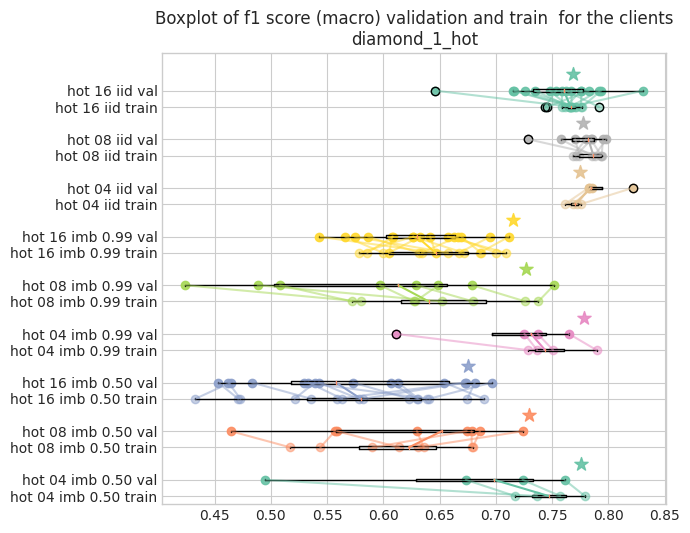

In [25]:
metric="global/val_f1"
metric="global/train_f1"
# for each sweep, plot the horizontal boxplot of the metric of all the clients
# the x axis is the metric
# the y axis is the sweep name
plt.clf()
plt.figure(figsize=(7,5))

# decide colors taking them from the seaborn palette Set2
colors = sns.color_palette("Set2", len(scores_dict.keys()))

tr_index = 5
val_index = 6
test_index = 7

for i,s in enumerate(scores_dict.keys()):
    label = " ".join(s.split("_")[3:])
    # save the median of the boxplot
    plt.boxplot(scores_dict[s][tr_index],positions=[3*i],vert=False,labels=[label + " train"])
    plt.scatter(scores_dict[s][tr_index],np.repeat(3*i,len(scores_dict[s][tr_index])),alpha=0.5,color=colors[i])
    
    plt.boxplot(scores_dict[s][val_index],positions=[3*i+1],vert=False,labels=[label+" val"])
    plt.scatter(scores_dict[s][val_index],np.repeat(3*i+1,len(scores_dict[s][val_index])),alpha=0.9,color=colors[i])
    # plot a line between the two medians
    plt.plot([np.median(scores_dict[s][tr_index]),np.median(scores_dict[s][val_index])],[3*i,3*i+1],color=colors[i])
    # plot a line between each metric of the clients
    for j in range(len(scores_dict[s][val_index])):
        plt.plot([scores_dict[s][tr_index][j],scores_dict[s][val_index][j]],[3*i,3*i+1],color=colors[i],alpha=0.5)
    
    # plot the test score
    plt.scatter(scores_dict[s][test_index],
                3*i+2,
                s=100,
                color=colors[i],
                marker="*",
                alpha=0.9)

plt.tight_layout()
# plot title and axis labels
plt.title("Boxplot of f1 score (macro) validation and train  for the clients\n"+dt_name[0])
plt.grid(True)
plt.show()


ValueError: x and y must be the same size

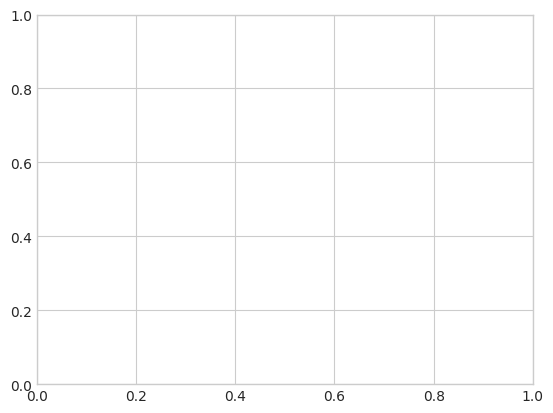

In [24]:

markers = ["o","d","s"]
# create colors with grading from normal color to dark
colors = sns.color_palette("Blues", n_colors=3)
# plot the global metric and the median of the boxplots
for i,s in enumerate(scores_dict.keys()):
    marker = 0 if "iid" in s else 1 if "imb_0.50" in s else 2
    marker = markers[marker]
    color = 0 if "4_" in s else 1 if "8_" in s else 2
    plt.scatter(scores_dict[s][-2],np.mean(scores_dict[s][-1]),alpha=0.9,s=100,
    marker=marker,color=colors[color],label=s)
#
# place the legend outside the plot
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left', borderaxespad=0.2)
# store the original y and x min and max
ymin, ymax = plt.ylim()
xmin, xmax = plt.xlim()
plt.plot([0,1],[0,1],color="black",alpha=0.5,ls="--")
# set the x and y limits to be the same
plt.ylim(ymin,ymax)
plt.xlim(xmin,xmax)
plt.title("Global "+metric+" vs median of the clients")
plt.ylabel("Median of the clients")
plt.xlabel("Global metric")
    

In [36]:
import os
# for each sweep load the npz file and memasure the f1 score macro of the baseine classifier that would calssify everything as the majority class


    



def get_val_set(dataset,distr,clients,client):
    data_folder = os.path.join(dataset,str(clients).zfill(3)+"_"+distr)
    client = str(client)
    val_name = data_folder.replace(os.path.sep, "_")+ "_train_"+client.zfill(3)+".npz"
    data_folder = os.path.join("Experiments",data_folder)
    #print(data_folder,val_name)
    data_path = os.path.join(data_folder,val_name)
    os.path.isfile(data_path)
    data = np.load(data_path)
    X_val = data["features"]
    y_val = data["labels"]
    
    return 

# test the function
num_clients = 8
c_id = 1
fn = get_val_set("adult_TargEncoded","imb_0.99",num_clients,c_id)


SyntaxError: invalid syntax (3157083394.py, line 9)

In [155]:
def get_f1_majority(targets,macro=True):
    # the armonic mean of precision and recall is 2*precision*recall/(precision+recall)
    # if the classifier always predict the majority class, then the precision is the ratio of the majority class, the recall is 1
    # the f1_macro is computed as the armonic mean of the precision macro and the recall macro
    r = np.max(targets.sum(axis=0))/len(targets)
    
    num_classes = targets.shape[1]
    print(r,num_classes)
    majority_f1 = 2*r/(r+1)
    return majority_f1/num_classes # the average
def get_f1_majority1(targets,macro=True):
    # the armonic mean of precision and recall is 2*precision*recall/(precision+recall)
    # if the classifier always predict the majority class, then the precision is the ratio of the majority class, the recall is 1
    # the f1_macro is computed as the armonic mean of the precision macro and the recall macro
    r = np.max(targets.sum(axis=0))/len(targets)
    # r is the precision on the majority class
    # the recall is 1
    # the macro precision is the average of the precision for each class
    # the macro recall is the average of the recall for each class
    # the macro f1 is the armomic mean of the macro precision and the macro recall
    num_classes = targets.shape[1]
    print(r,num_classes)
    macro_precision = r/num_classes
    macro_recall = 1/num_classes
    macro_f1 = 2*macro_precision*macro_recall/(macro_precision+macro_recall)
    return macro_f1
def get_f1_majority2(ratio,num_classes):
    return (2*ratio/(ratio+1))/num_classes # the average
from sklearn.metrics import f1_score, accuracy_score
predicted = np.zeros((10,2))
predicted[:,0] = 1
ta = np.zeros((10,2))
#ta[:-3,0] = 1
#ta[-3:-2,1] = 1
#ta[-2:,2] = 1
ta[:,0] = 1

get_f1_majority(ta),get_f1_majority1(ta),f1_score(ta,predicted,average="macro"),accuracy_score(ta,predicted)

1.0 2
1.0 2


c:\Users\Valerio\Documents\VirtualEnvs\env_FLXAI\lib\site-packages\sklearn\metrics\_classification.py:1609: UndefinedMetricWarning: F-score is ill-defined and being set to 0.0 in labels with no true nor predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, "true nor predicted", "F-score is", len(true_sum))


(0.5, 0.5, 0.5, 1.0)

In [164]:
get_f1_majority2(0.85,2)

0.45945945945945943